# 09. Comparación de M0, M1 y M2

Se comparan las predicciones ya guardadas para las mismas 454 publicaciones bolivianas.
M0 es el clasificador base, M1 se ajustó con SMPS y M2 continuó desde M1 con datos bolivianos.
Este cuaderno usa los resultados de la evaluación en 06–08 y verifica sus huellas y el
emparejamiento por identificador y etiqueta humana.

M1 y M2 se ajustaron durante tres épocas por etapa. M0 conserva los pesos publicados.

La corrida se elige en `corrida.json`. Las evaluaciones reproducidas se guardan en `salidas/<ejecución>/evaluacion`.

Si abres este cuaderno directamente en Colab, ejecuta su primera celda y autoriza Google Drive cuando se solicite. Para recorrer toda la secuencia de una vez, usa `INICIAR_EN_COLAB.ipynb`.

**Salidas guardadas.** Las tablas, figuras y registros visibles proceden de la corrida original `corrida_03_epocas`. Esta copia incorpora las preguntas de carga de 06–08. Las salidas y los números de ejecución conservan su origen histórico. Abre el cuaderno y desplázate para exponer los resultados.

In [1]:
# Inicio al abrir este cuaderno directamente en Google Colab.
from pathlib import Path

if not Path("corrida.json").is_file():
    import os
    import subprocess
    import sys

    try:
        from google.colab import drive
    except ImportError as error:
        raise FileNotFoundError("En Jupyter, abre la carpeta que contiene corrida.json.") from error

    proyecto_drive = Path("/content/drive/MyDrive/Tesis_RoBERTuito_M0_M1_M2")
    if not (proyecto_drive / "corrida.json").is_file():
        drive.mount("/content/drive", timeout_ms=180000)
    if not (proyecto_drive / "corrida.json").is_file():
        raise FileNotFoundError("Busca Tesis_RoBERTuito_M0_M1_M2 directamente en Mi unidad.")

    os.chdir(proyecto_drive)
    sys.path.insert(0, str(proyecto_drive))
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r",
         str(proyecto_drive / "requirements-cuadernos.txt")],
        check=True,
    )
    print("Carpeta de la tesis conectada:", proyecto_drive)

from rutas import carpeta_salidas

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from evaluar import CLASES, FUENTE, leer_particion, mostrar_cuadro, resumir, sha256

raiz = Path.cwd()
corrida = json.loads((raiz / "corrida.json").read_text(encoding="utf-8"))["corrida"]
particion = raiz / "insumos/particion_boliviana.xlsx"
modelos = ["M0", "M1", "M2"]
huella_particion = sha256(particion)
prueba = leer_particion(particion)
referencia = prueba.set_index("id")["etiqueta_humana"].rename("referencia").sort_index()

resultados = {}
matrices = {}
for nombre in modelos:
    archivo = carpeta_salidas(raiz) / "evaluacion" / corrida / f"{nombre}.json"
    if not archivo.is_file():
        archivo = raiz / "evaluacion" / corrida / f"{nombre}.json"
    evidencia = json.loads(archivo.read_text(encoding="utf-8"))
    pesos = raiz / "modelos" / corrida / nombre / "model.safetensors"
    if (evidencia["modelo"], evidencia["corrida"], evidencia["subconjunto"]) != (nombre, corrida, "validacion"):
        raise ValueError(f"La evaluación de {nombre} no corresponde a esta corrida y partición.")
    if evidencia["particion_sha256"] != huella_particion or evidencia["pesos_sha256"] != sha256(pesos):
        raise ValueError(f"La partición o los pesos de {nombre} cambiaron.")
    filas = pd.DataFrame(evidencia["predicciones"]).set_index("id").sort_index()
    if not filas["referencia"].equals(referencia) or not set(filas["prediccion"]) <= set(CLASES):
        raise ValueError(f"Identificadores, referencias o predicciones inconsistentes en {nombre}.")
    resultados[nombre], matrices[nombre] = resumir(filas)

tabla = pd.DataFrame.from_dict(resultados, orient="index")
tabla["Aciertos"] = [int(matrices[nombre].to_numpy().trace()) for nombre in modelos]
tabla["Publicaciones"] = len(referencia)
mostrar_cuadro("Cuadro 1. Resultados en la partición de evaluación", tabla)

,Exactitud,F1 macro,Aciertos,Publicaciones
M0,79.96%,63.86%,363,454
M1,76.21%,63.71%,346,454
M2,88.33%,77.61%,401,454


El Cuadro 1 y la Figura 1 comparan la proporción de aciertos y el F1 macro. En esta partición,
326 publicaciones tienen etiqueta negativa, 94 neutral y 34 positiva. El F1 macro da el mismo
peso a las tres clases al resumir su desempeño.

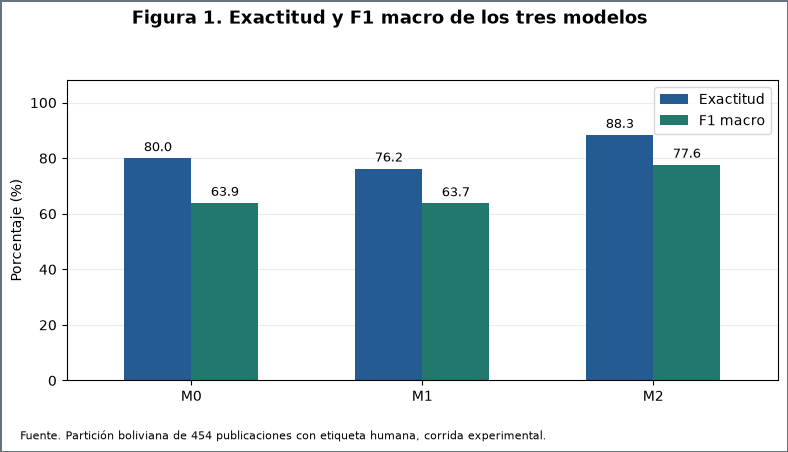

In [2]:
fig, ax = plt.subplots(figsize=(8.4, 4.5))
fig.patch.set_edgecolor("#667480")
fig.patch.set_linewidth(1)
fig.suptitle("Figura 1. Exactitud y F1 macro de los tres modelos", fontsize=13, fontweight="bold")
(tabla[["Exactitud", "F1 macro"]] * 100).plot.bar(
    ax=ax, color=["#245b93", "#23786e"], width=0.58, rot=0,
)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", padding=3, fontsize=9)
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 108)
ax.set_yticks(range(0, 101, 20))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
fig.text(0.06, 0.025, f"Fuente. {FUENTE}", fontsize=8)
fig.tight_layout(rect=(0.03, 0.07, 0.98, 0.93))
plt.show()

En la Figura 2, la fila indica la clase asignada por la persona anotadora y la columna
la predicción. La diagonal cuenta los aciertos por clase. Las tres matrices usan la misma
escala de color.

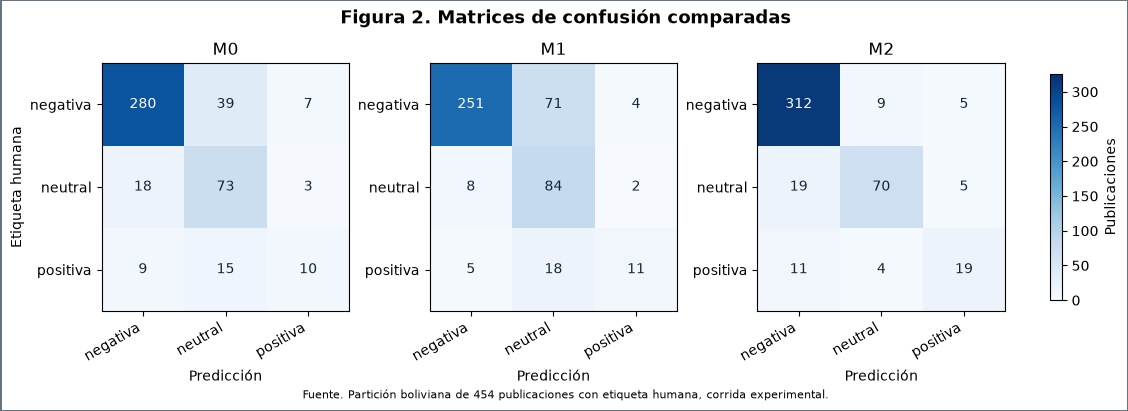

In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(11.2, 4), layout="constrained")
fig.patch.set_edgecolor("#667480")
fig.patch.set_linewidth(1)
fig.suptitle("Figura 2. Matrices de confusión comparadas", fontsize=13, fontweight="bold")
maximo = int(referencia.value_counts().max())
for ax, nombre in zip(ejes, modelos):
    valores = matrices[nombre].to_numpy()
    imagen = ax.imshow(valores, cmap="Blues", vmin=0, vmax=maximo)
    ax.set_title(nombre)
    ax.set_xticks(range(3), CLASES, rotation=30, ha="right")
    ax.set_yticks(range(3), CLASES)
    ax.set_xlabel("Predicción")
    for fila in range(3):
        for columna in range(3):
            valor = valores[fila, columna]
            color = "white" if valor > maximo / 2 else "#15263a"
            ax.text(columna, fila, valor, ha="center", va="center", color=color)
ejes[0].set_ylabel("Etiqueta humana")
fig.colorbar(imagen, ax=ejes, shrink=0.75, label="Publicaciones")
fig.supxlabel(f"Fuente. {FUENTE}", fontsize=8)
plt.show()

Las diferencias describen esta partición. La corrida de entrenamiento se completó antes
de producir estas predicciones y las comparaciones conservan los pesos guardados.